In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
print("Datset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Datset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nnumber of duplicate rows:", df.duplicated().sum())


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

number of duplicate rows: 0


In [5]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("Missing values after imputation:")
print(df[["Age", "Embarked", "Cabin"]].isnull().sum())

Missing values after imputation:
Age           0
Embarked      0
Cabin       687
dtype: int64


In [6]:
df = df.drop(columns=["Cabin"])
print("Dataset shape after dropping Cabin:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())

Dataset shape after dropping Cabin: (891, 11)
Remaining missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [9]:
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


### Duplicate Removal

The dataset was checked for duplicate rows using `df.duplicated().sum()`. No duplicate rows were found, so no rows needed to be removed.

In [7]:
df = df.drop(columns=["PassengerId", "Name", "Ticket"])
print("Dataset shape after feature selection:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())
df.head()

Dataset shape after feature selection: (891, 8)

Remaining columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## Feature Selection
The PassengerId, Name, and Ticket columns were removed because they are not required for this basic preprocessing exercise. The Survived column was retained as the target variable for potential survival prediction.

In [8]:
df = pd.get_dummies(df, columns = ["Sex", "Embarked"], dtype = int)
print("Dataset shape aafter encoding:", df.shape)
print("\nUpdated columns:")
print(df.columns.tolist())
df.head()

Dataset shape aafter encoding: (891, 11)

Updated columns:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,0,1,0,0,1


## Categorical Encoding
One-hot encoding was applied to the Sex and Embarked columns to convert categorical values into numerical features suitable for machine learning algorithms.

In [9]:
import sklearn
print(sklearn.__version__)

1.7.2


In [10]:
from sklearn.preprocessing import MinMaxScaler
print("MinMaxScaler imported successfully!")

MinMaxScaler imported successfully!


In [11]:
from sklearn.preprocessing import MinMaxScaler
columns_to_scale = ["Age", "Fare"]
scaler = MinMaxScaler()
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
print("Dataset after normalization:")
print(df[columns_to_scale].head())

print("\nminimum values:")
print(df[columns_to_scale].head())

print("\nMaximum values:")
print(df[columns_to_scale].max())


Dataset after normalization:
        Age      Fare
0  0.271174  0.014151
1  0.472229  0.139136
2  0.321438  0.015469
3  0.434531  0.103644
4  0.434531  0.015713

minimum values:
        Age      Fare
0  0.271174  0.014151
1  0.472229  0.139136
2  0.321438  0.015469
3  0.434531  0.103644
4  0.434531  0.015713

Maximum values:
Age     1.0
Fare    1.0
dtype: float64


In [12]:
print("Actual minimum values:")
print(df[["Age", "Fare"]].min())
print("\nActual maximum values:")
print(df[["Age", "Fare"]].max())

Actual minimum values:
Age     0.0
Fare    0.0
dtype: float64

Actual maximum values:
Age     1.0
Fare    1.0
dtype: float64


## Feature Normalization
Min-Max Scaling was applied to the Age and fare columns using MinMaxScaler.The values were scaled to a range between 0 and 1, making the numerical features comparable.

In [13]:
survival_counts = df["Survived"].value_counts().sort_index()
print("Survival Counts:")
print("Did not survive (0)", survival_counts[0])
print("survived (1):", survival_counts[1])

Survival Counts:
Did not survive (0) 549
survived (1): 342


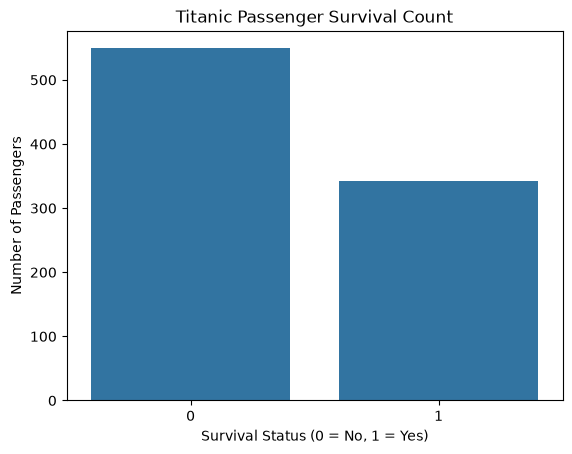

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data = df, x = "Survived")
plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

## Exploratory Data Analysis

The survival status of passengers was analysed using counts and a bar chart. The visualization compares the number of passengers who survived with those who did not survive.

In [15]:
df["Gender"] = df["Sex_female"].map({
    1: "Female",
    0: "Male"
})
gender_survival = df.groupby("Gender")["Survived"].mean() * 100
print("Survival rate by gender(%):")
print(gender_survival)

Survival rate by gender(%):
Gender
Female    74.203822
Male      18.890815
Name: Survived, dtype: float64


## Gender-Based Survival Analysis

The survival rate was calculated separately for female and male passengers. This analysis helps identify differences in survival outcomes between the two groups.

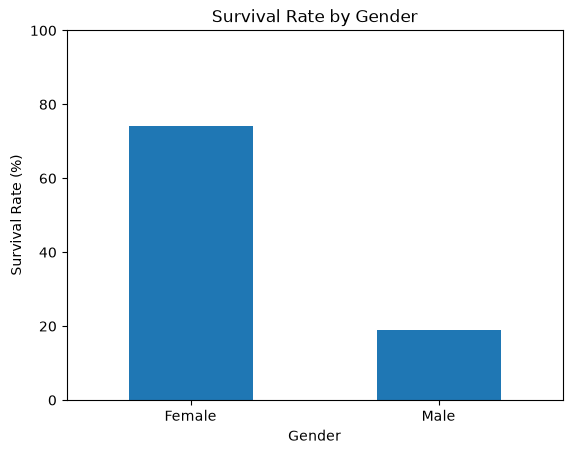

In [16]:
gender_survival.plot(kind = "bar")
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

In [17]:
print("Final Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nFinal Dataset Preview")
display(df.head())

Final Dataset Shape: (891, 12)

Missing Values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
Gender        0
dtype: int64

Duplicate Rows: 116

Final Dataset Preview


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Gender
0,0,3,0.271174,1,0,0.014151,0,1,0,0,1,Male
1,1,1,0.472229,1,0,0.139136,1,0,1,0,0,Female
2,1,3,0.321438,0,0,0.015469,1,0,0,0,1,Female
3,1,1,0.434531,1,0,0.103644,1,0,0,0,1,Female
4,0,3,0.434531,0,0,0.015713,0,1,0,0,1,Male


## Conclusion
The Titanic dataset was successfully preprocessed using Python, Pandas, NumPy, and Scikit-learn. Missing values were handled, unnecessary columns were removed, and categorical variables were converted into numerical features using one-hot encoding. Min-Max normalization was applied to the Age and Fare columns. Exploratory Data Analysis was performed using visualizations to study passenger survival patterns. The analysis showed that female passengers had a higher survival rate than male passengers in this dataset.